# 03 · Priors and sensitivity

The trace prior $\mu$ is part of the metric. It factorizes into a length prior $\rho$ and an activity prior $\pi$:

$$\mu_{\rho,\pi}(\langle a_1,\dots,a_n\rangle) = \rho_n \prod_{i=1}^n \pi(a_i)$$

| length prior | $\rho_n$ | parameter |
|---|---|---|
| `geometric` | $(1-\lambda)\lambda^n$ | $0<\lambda<1$ |
| `power_law` | $(n+1)^{-\alpha}/\zeta(\alpha)$ | $\alpha>1$ |

| activity prior | $\pi(a)$ |
|---|---|
| `uniform` | $1/\lvert\Sigma\rvert$ |
| `empirical` | $(c(a)+\delta)/(N+\delta\lvert\Sigma\rvert)$, Laplace-smoothed log frequencies |
| mapping | any full-support distribution you declare |

The prior is a declared reference measure. It is not estimated from trace frequencies and does not model stochastic process behaviour.

In [1]:
import os, warnings
os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "False"
warnings.filterwarnings("ignore", category=DeprecationWarning)

import language_mass_precision as lmp
import pm4py
import pandas as pd
pd.set_option("display.precision", 6)
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kendalltau
from sklearn.model_selection import ParameterGrid

## Calibration from the log

When `length_parameter` is left as `None`, the length prior is calibrated so that half of its mass lies on traces no longer than the median variant length $\ell_{50}$. For the geometric prior this gives $\lambda_{50} = 2^{-1/(\ell_{50}+1)}$.

In [2]:
for median in (3, 8, 15):
    geo = lmp.GeometricLengthPrior.from_median_length(median)
    pw = lmp.PowerLawLengthPrior.from_median_length(median)
    print(f"l50={median:>2}  lambda={geo.lam:.4f}  P(n<=l50)={geo.cdf(median):.3f}   "
          f"alpha={pw.alpha:.4f}  P(n<=l50)={pw.cdf(median):.3f}")

l50= 3  lambda=0.8409  P(n<=l50)=0.500   alpha=1.3374  P(n<=l50)=0.500
l50= 8  lambda=0.9259  P(n<=l50)=0.500   alpha=1.2469  P(n<=l50)=0.500
l50=15  lambda=0.9576  P(n<=l50)=0.500   alpha=1.2062  P(n<=l50)=0.500


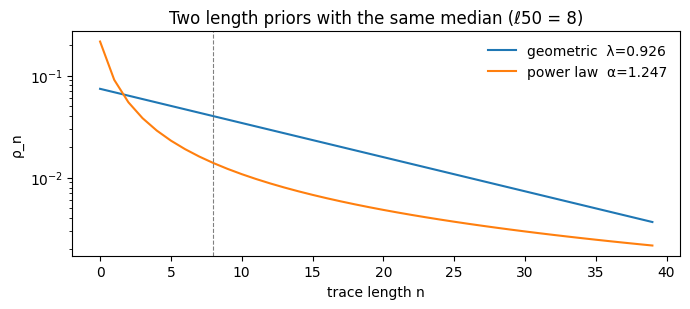

In [3]:
n = np.arange(0, 40)
geo = lmp.GeometricLengthPrior.from_median_length(8)
pw = lmp.PowerLawLengthPrior.from_median_length(8)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(n, [geo.rho(k) for k in n], label=f"geometric  λ={geo.lam:.3f}")
ax.plot(n, [pw.rho(k) for k in n], label=f"power law  α={pw.alpha:.3f}")
ax.axvline(8, color="grey", lw=0.8, ls="--")
ax.set_yscale("log"); ax.set_xlabel("trace length n"); ax.set_ylabel("ρ_n")
ax.set_title("Two length priors with the same median (ℓ50 = 8)")
ax.legend(frameon=False); fig.tight_layout()

The power law keeps far more mass on long traces. That matters for models with loops, whose languages extend to arbitrary length.

## Sweeping the prior without recompiling

The estimator resolves the prior at score time. Compile each model once and sweep any grid, for example with scikit-learn's `ParameterGrid`.

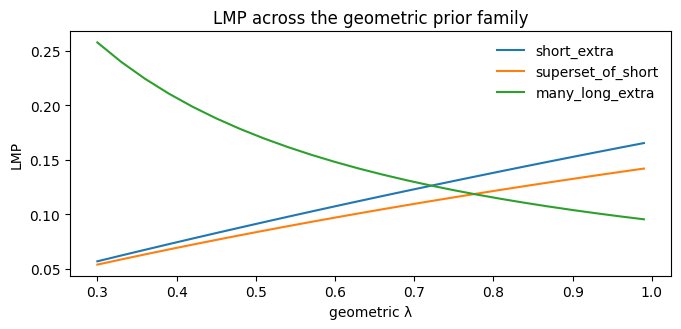

In [4]:
log = [("a", "b")]
models = {
    "short_extra":       pm4py.parse_process_tree("X(->('a','b'), 'c')"),
    "superset_of_short": pm4py.parse_process_tree("X(->('a','b'), 'c', ->('d','e'))"),
    "many_long_extra":   pm4py.parse_process_tree(
        "X(->('a','b'), ->(X('a','c','d','e'), X('a','c','d','e'), X('c','d','e')))"),
}
estimator = lmp.LanguageMassPrecision(alphabet="abcde").fit(log)
compiled = {name: estimator.compile(m, name=name) for name, m in models.items()}

rows = []
for params in ParameterGrid({"length_prior": ["geometric"], "length_parameter": np.linspace(0.3, 0.99, 24)}):
    estimator.set_params(**params)
    rows.append({"lambda": params["length_parameter"],
                 **{name: estimator.score(c).value for name, c in compiled.items()}})
sweep = pd.DataFrame(rows).set_index("lambda")

fig, ax = plt.subplots(figsize=(7, 3.4))
sweep.plot(ax=ax)
ax.set_xlabel("geometric λ"); ax.set_ylabel("LMP"); ax.set_title("LMP across the geometric prior family")
ax.legend(frameon=False); fig.tight_layout()

Two patterns appear, and both are what the theory predicts.

* `short_extra` ⊂ `superset_of_short`: their languages are **nested** and they share the fitting part, so `short_extra` ranks above its superset for **every** prior. No choice of $\mu$ can reverse an inclusion-based comparison.
* `short_extra` and `many_long_extra` are **incomparable** languages: one adds a single short unseen trace, the other many longer ones. Which costs more depends on how much mass the prior puts on short versus long traces, and the ranking legitimately flips near $\lambda \approx 0.75$.

In [5]:
ranks = sweep.rank(axis=1, ascending=False)
reference = ranks.iloc[0]
pd.DataFrame({
    "kendall_tau_vs_first": ranks.apply(lambda r: kendalltau(reference, r).statistic, axis=1),
    "short > superset": sweep["short_extra"] > sweep["superset_of_short"],
    "short > many_long": sweep["short_extra"] > sweep["many_long_extra"],
}).iloc[::3]

,kendall_tau_vs_first,short > superset,short > many_long
lambda,,,
0.30,1.000000,True,False
0.39,1.000000,True,False
0.48,1.000000,True,False
0.57,1.000000,True,False
0.66,1.000000,True,False
0.75,0.333333,True,True
0.84,-0.333333,True,True
0.93,-0.333333,True,True


## The activity prior

The uniform activity prior treats every activity alike. The empirical prior weights activities by their (smoothed) log frequency, so unseen behaviour built from frequent activities becomes more costly.

In [6]:
log = {("a", "b", "c"): 50, ("a", "c"): 50, ("a", "b", "d"): 1}
models = {
    "frequent_extra": pm4py.parse_process_tree("->('a', X(->('b', X('c','d')), 'c', ->('c', 'c')))"),
    "rare_extra":     pm4py.parse_process_tree("->('a', X(->('b', X('c','d')), 'c', ->('d', 'd')))"),
}
pd.concat({
    prior: lmp.rank_models(log, models, activity_prior=prior).set_index("model")[["rank", "value"]]
    for prior in ("uniform", "empirical")
}, axis=1)

uniform           empirical         
                  rank     value      rank    value
model                                              
frequent_extra       1  0.871081         2  0.78027
rare_extra           1  0.871081         1  0.99989

Under the uniform prior the two unseen traces `a c c` and `a d d` weigh the same and the models tie. The empirical prior makes `c` far more likely than `d`, so the frequent-activity extension costs more precision. Whether that is desirable is a modelling decision; the library makes it explicit and reproducible.

## Certified ordering

Under the power-law prior, cyclic models yield certified intervals. `certainly_greater` reports whether two intervals prove an ordering.

In [7]:
loop_small = pm4py.parse_process_tree("->('a', *('b', tau), 'c')")
loop_large = pm4py.parse_process_tree("->('a', *(X('b', 'd'), tau), 'c')")
log = [("a", "b", "c"), ("a", "b", "b", "c")]
r_small = lmp.precision_language_mass(log, loop_small, length_prior="power_law", alphabet="abcd")
r_large = lmp.precision_language_mass(log, loop_large, length_prior="power_law", alphabet="abcd")
print(r_small); print(r_large)
print("certified small > large:", r_small.certainly_greater(r_large))

LMPResult(status=interval, lower=0.962437, upper=0.962437, width=8e-07, certification='deterministic_interval')
LMPResult(status=interval, lower=0.365069, upper=0.365069, width=2.9e-07, certification='deterministic_interval')
certified small > large: True
